# Encoder-decoder Transformer: date normalization

The full architecture from *Attention Is All You Need*, built from the same hand-written [`transformer.py`](transformer.py) blocks as MiniGPT.

**Task:** read a date written in any of several formats and output it in ISO form.

```
"Saturday, 31 October 2026"  ->  "2026-10-31"
"Oct 31 2026"                ->  "2026-10-31"
"31.10.2026"                 ->  "2026-10-31"
```

This needs all three kinds of attention:

| part | attention | mask |
|---|---|---|
| encoder | self-attention over the input | **bidirectional** + **padding mask** |
| decoder | self-attention over what it has written | **causal** |
| decoder | **cross-attention**: decoder queries, encoder keys/values | padding mask on the encoder side |

The task trains in a couple of minutes on a CPU, and the result is easy to check: either the output date is correct or it isn't.

In [1]:
import random, datetime, time
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from transformer import Seq2Seq

random.seed(0); torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## Data

Training examples are generated on the fly. Every 10th day is held out of training, so the test set contains dates the model has **never seen**.

In [2]:
FORMATS = ["%d %b %Y", "%B %d, %Y", "%A, %d %B %Y", "%d.%m.%Y", "%b %d %Y", "%a %d %b %Y"]
START, N_DAYS = datetime.date(1950, 1, 1), 100 * 365

def make_example(held_out):
    while True:
        n = random.randrange(N_DAYS)
        if (n % 10 == 0) == held_out:
            break
    d = START + datetime.timedelta(days=n)
    return d.strftime(random.choice(FORMATS)), d.isoformat()

PAD, BOS, EOS = 0, 1, 2
chars = sorted(set("0123456789-., ") | set("".join(
    datetime.date(2000, m, d).strftime("%A %B %a %b") for m in range(1, 13) for d in range(1, 8))))
itos = ["<pad>", "<bos>", "<eos>"] + chars
stoi = {c: i for i, c in enumerate(itos)}
vocab_size = len(itos)

def to_tensor(seqs):
    width = max(map(len, seqs))
    return torch.tensor([s + [PAD] * (width - len(s)) for s in seqs], device=device)

def make_batch(n, held_out=False):
    pairs = [make_example(held_out) for _ in range(n)]
    src = to_tensor([[stoi[c] for c in s] for s, _ in pairs])
    tgt = [[stoi[c] for c in t] for _, t in pairs]
    tgt_in = to_tensor([[BOS] + t for t in tgt])     # teacher forcing: decoder sees the true prefix
    tgt_out = to_tensor([t + [EOS] for t in tgt])    # ...and predicts the next char
    return src, tgt_in, tgt_out, pairs

for s, t in make_batch(4)[3]:
    print(f"{s!r:32} -> {t!r}")
print("vocab size:", vocab_size)

'15.02.2019'                     -> '2019-02-15'
'Sunday, 07 April 1957'          -> '1957-04-07'
'26.09.2041'                     -> '2041-09-26'
'Sunday, 28 August 2022'         -> '2022-08-28'
vocab size: 46


## Model and training

0.94M parameters


step    0 | loss 3.9364 | 0s


step  250 | loss 0.0131 | 38s


step  500 | loss 0.0061 | 78s


step  750 | loss 0.0006 | 117s


step 1000 | loss 0.0016 | 158s


step 1250 | loss 0.0002 | 199s


step 1500 | loss 0.0015 | 240s


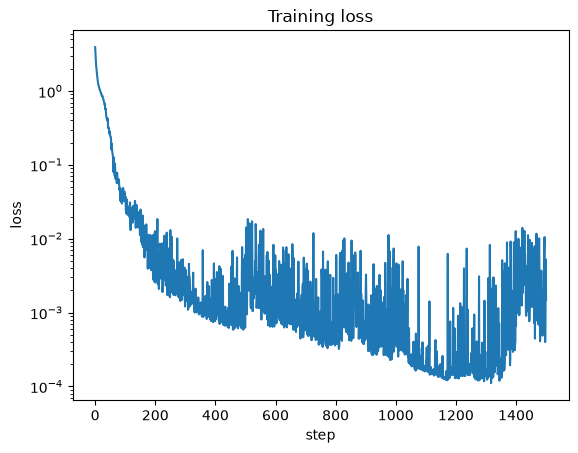

In [3]:
model = Seq2Seq(vocab_size, max_len=32, dim=128, n_blocks=2, n_heads=4, pad_id=PAD, dropout=0.1).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
steps, history = 1500, []
start = time.time()
model.train()
for step in range(steps + 1):
    src, tgt_in, tgt_out, _ = make_batch(128)
    logits = model(src, tgt_in)
    loss = F.cross_entropy(logits.view(-1, vocab_size), tgt_out.view(-1), ignore_index=PAD)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    history.append(loss.item())
    if step % 250 == 0:
        print(f"step {step:4d} | loss {loss.item():.4f} | {time.time() - start:.0f}s")

plt.plot(history); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss")
plt.show()

## Evaluation on unseen dates

Greedy decoding: the encoder runs **once**, then the decoder writes one character at a time, attending to its own output so far (causal) and to the encoder (cross-attention).

In [4]:
def predict(src):
    out = model.greedy(src, BOS, EOS, max_new=12)[:, 1:].tolist()
    return ["".join(itos[i] for i in row[: row.index(EOS)] if i >= 3) if EOS in row else "" for row in out]

src, _, _, pairs = make_batch(1000, held_out=True)
preds = predict(src)
correct = sum(p == t for p, (_, t) in zip(preds, pairs))
print(f"exact-match accuracy on 1000 unseen dates: {correct / 10:.1f}%\n")
for (s, t), p in list(zip(pairs, preds))[:8]:
    print(f"{s!r:32} -> {p!r:14} {'ok' if p == t else 'WRONG, expected ' + t}")

exact-match accuracy on 1000 unseen dates: 99.7%

'14 Nov 2042'                    -> '2042-11-14'   ok
'Dec 23 2006'                    -> '2006-12-23'   ok
'04.07.1993'                     -> '1993-07-04'   ok
'Monday, 09 June 1952'           -> '1952-06-09'   ok
'April 30, 1952'                 -> '1952-04-30'   ok
'June 01, 1967'                  -> '1967-06-01'   ok
'Wednesday, 10 July 2030'        -> '2030-07-10'   ok
'Wednesday, 16 August 2023'      -> '2023-08-16'   ok


## Cross-attention: which input characters each output character reads

Each row is an output character and each column an input character. A trained model learns to **align** them: the year digits read the year, the month digits read the month *name* (`Oct` -> `10`), and so on. This is the same alignment mechanism that makes Transformer translation work.

Below that is the encoder's self-attention. Because it's bidirectional, the full matrix is used, with no triangle.

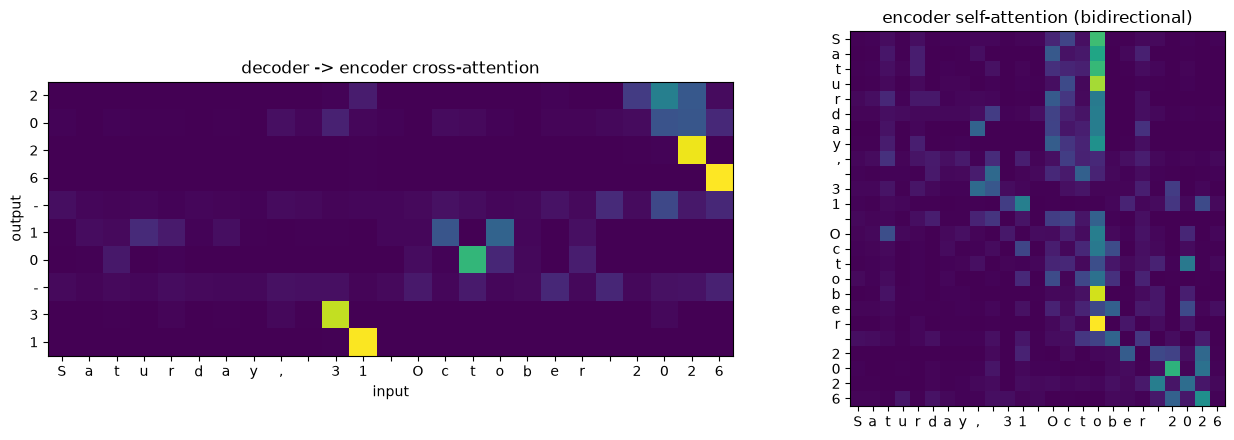

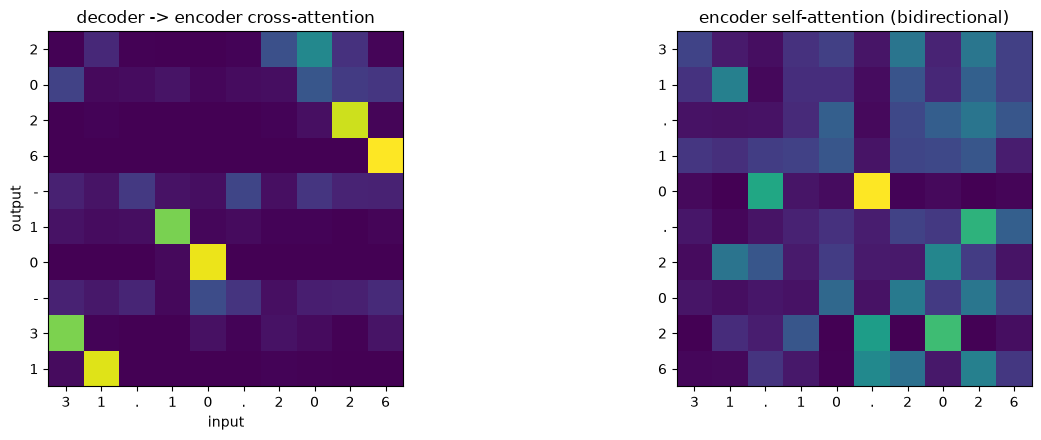

In [5]:
def show_attention(text):
    src = to_tensor([[stoi[c] for c in text]])
    pred = predict(src)[0]
    tgt_in = to_tensor([[BOS] + [stoi[c] for c in pred]])
    with torch.no_grad():
        model(src, tgt_in)                                          # fills attn_weights (eval mode)
    cross = model.decoder[-1].cross_attn.attn_weights[0].mean(0)   # avg over heads -> (T_out, T_in)
    enc = model.encoder[-1].self_attn.attn_weights[0].mean(0)      # (T_in, T_in)

    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [len(text), len(text)]})
    a.imshow(cross[:-1].cpu(), cmap="viridis")                     # drop the <eos> row
    a.set_xticks(range(len(text)), list(text)); a.set_yticks(range(len(pred)), list(pred))
    a.set_title("decoder -> encoder cross-attention"); a.set_xlabel("input"); a.set_ylabel("output")
    b.imshow(enc.cpu(), cmap="viridis")
    b.set_xticks(range(len(text)), list(text)); b.set_yticks(range(len(text)), list(text))
    b.set_title("encoder self-attention (bidirectional)")
    plt.tight_layout(); plt.show()

show_attention("Saturday, 31 October 2026")
show_attention("31.10.2026")